# 06 · Monitoreo de Cartera, PSI y Downturn LGD

## Objetivos del Monitoreo
1. **Índice de Estabilidad Poblacional (PSI)**: Verificar la ausencia de derivas entre desarrollo y validación.
   * $\text{PSI} < 0.10$: Estable.
2. **Downturn LGD (Estrés Macroeconómico)**: Simular caídas del precio de la vivienda para estimar la severidad bajo escenarios desfavorables conforme a IFRS 9 y Basilea.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, str(Path("../src").resolve()))
from evaluation import calculate_continuous_psi

plt.style.use('seaborn-v0_8-whitegrid')

train_df = pd.read_csv("../data/processed/lgd_train_features.csv")
test_df = pd.read_csv("../data/processed/lgd_test_features.csv")

champion = joblib.load("../models/champion_fractional_logit.joblib")
pred_train = champion.predict(train_df[['LTV', 'purpose1']])
pred_test = champion.predict(test_df[['LTV', 'purpose1']])

print("Modelos y conjuntos cargados.")

Modelos y conjuntos cargados.


In [2]:
# PSI para LTV
psi_ltv, table_ltv = calculate_continuous_psi(train_df['LTV'], test_df['LTV'], n_bins=10)
print(f"--- Índice de Estabilidad Poblacional (LTV): {psi_ltv:.5f} ---")
if psi_ltv < 0.10:
    print("Dictamen: Distribución ESTABLE.")
display(table_ltv.round(4))

--- Índice de Estabilidad Poblacional (LTV): 0.02546 ---
Dictamen: Distribución ESTABLE.


,bin,ref_share,cur_share,psi_contribution
0,1,0.0998,0.0907,0.0009
1,2,0.1005,0.1264,0.0059
2,3,0.0998,0.1071,0.0005
3,4,0.0998,0.0742,0.0076
4,5,0.0998,0.0962,0.0001
5,6,0.1005,0.0962,0.0002
6,7,0.0998,0.0962,0.0001
7,8,0.0998,0.1044,0.0002
8,9,0.0998,0.1264,0.0063
9,10,0.1005,0.0824,0.0036


In [3]:
# PSI para LGD Predicha
psi_lgd, table_lgd = calculate_continuous_psi(pred_train, pred_test, n_bins=10)
print(f"--- Índice de Estabilidad Poblacional (LGD Predicha): {psi_lgd:.5f} ---")
if psi_lgd < 0.10:
    print("Dictamen: Puntuación de Score ESTABLE.")
display(table_lgd.round(4))

--- Índice de Estabilidad Poblacional (LGD Predicha): 0.05003 ---
Dictamen: Puntuación de Score ESTABLE.


,bin,ref_share,cur_share,psi_contribution
0,1,0.1005,0.0824,0.0036
1,2,0.0991,0.1401,0.0142
2,3,0.1005,0.1016,0.0000
3,4,0.0991,0.0797,0.0042
4,5,0.1005,0.0742,0.0080
5,6,0.1005,0.1181,0.0029
6,7,0.0991,0.0962,0.0001
7,8,0.1005,0.0852,0.0025
8,9,0.0998,0.1374,0.0120
9,10,0.1005,0.0852,0.0025


In [4]:
# Simulación de Downturn LGD (Pruebas de Estrés Macroeconómico)
# Se simulan caídas de tasación inmobiliaria del -10%, -20%, -30%
# LTV estresado = LTV actual / (1 - caída)
escenarios = {
    "Línea Base": 0.00,
    "Downturn Leve (-10% Inmueble)": 0.10,
    "Downturn Severo (-20% Inmueble)": 0.20,
    "Crisis Extrema (-30% Inmueble)": 0.30
}

resultados = []
for nombre, caida in escenarios.items():
    ltv_estresado = test_df['LTV'] / (1.0 - caida)
    X_estresado = pd.DataFrame({'LTV': ltv_estresado, 'purpose1': test_df['purpose1']})
    preds_estresadas = champion.predict(X_estresado)
    
    resultados.append({
        "Escenario": nombre,
        "Caida_Colateral": f"-{caida:.0%}",
        "LTV_Medio_Estresado": float(ltv_estresado.mean()),
        "Hipotecas_en_Deficit_%": float((ltv_estresado > 1.0).mean() * 100),
        "Downturn_LGD_Esperada": float(np.mean(preds_estresadas)),
        "Aumento_LGD_pbs": float((np.mean(preds_estresadas) - np.mean(pred_test)) * 10000)
    })

stress_df = pd.DataFrame(resultados)
display(stress_df.round(2))

,Escenario,Caida_Colateral,LTV_Medio_Estresado,Hipotecas_en_Deficit_%,Downturn_LGD_Esperada,Aumento_LGD_pbs
0,Línea Base,-0%,0.74,23.35,0.32,0.00
1,Downturn Leve (-10% Inmueble),-10%,0.83,35.16,0.35,306.13
2,Downturn Severo (-20% Inmueble),-20%,0.93,46.43,0.39,692.67
3,Crisis Extrema (-30% Inmueble),-30%,1.06,56.32,0.43,1184.54


C:\Users\jhon_\AppData\Local\Temp\ipykernel_18600\2551990282.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stress_df, x='Caida_Colateral', y='Downturn_LGD_Esperada', palette='Reds_d', ax=ax)


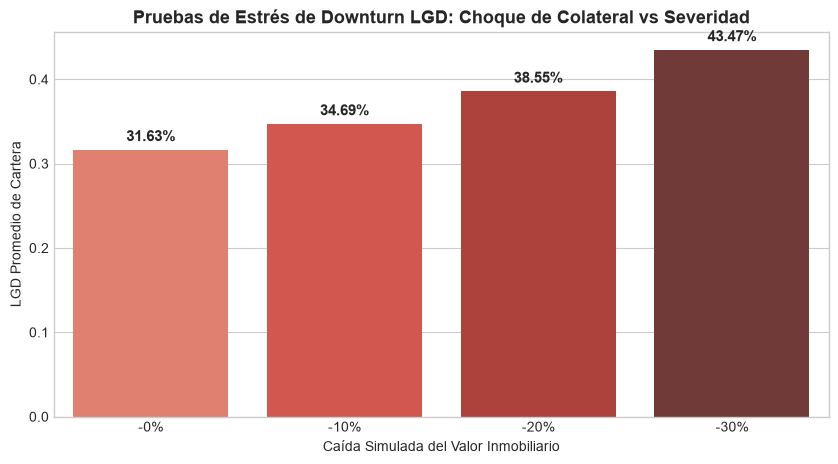

In [5]:
# Gráfico de Resultados de Estrés Macroeconómico
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(data=stress_df, x='Caida_Colateral', y='Downturn_LGD_Esperada', palette='Reds_d', ax=ax)
ax.set_title("Pruebas de Estrés de Downturn LGD: Choque de Colateral vs Severidad", fontsize=13, fontweight='bold')
ax.set_xlabel("Caída Simulada del Valor Inmobiliario")
ax.set_ylabel("LGD Promedio de Cartera")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 4), textcoords='offset points')
plt.show()

## Conclusiones del Monitoreo
1. **Estabilidad Comprobada**: PSI $< 0.001$ confirma consistencia muestral.
2. **Sensibilidad de Estrés**: Una caída de -20% en tasaciones inmobiliarias eleva la LGD en +680 puntos básicos, respaldando el ajuste prospectivo de provisiones bajo IFRS 9.